# Tugas 4 Big Data — Analisis Sentimen Neural Network
**Topik: Kebakaran Hutan (Karhutla)**

Alur: pengambilan data → cleansing → pelabelan rule-based → distribusi → WordCloud → MLP (TF-IDF) → evaluasi → prediksi teks baru.

> **Catatan data:** `tweet_data.csv` pada folder ini adalah **dataset simulasi** (400 tweet) berformat sama dengan hasil crawling
> (`created_at`, `username`, `full_text`), karena crawling X/Twitter butuh login/token. Untuk data asli, jalankan `crawling_twitter.py`
> lalu jalankan ulang notebook ini dari atas.

## Langkah 1 — Pengambilan Data

In [4]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("tweet_data.csv")
print("Jumlah data:", len(df), "(minimal 300)")
print(df.columns.tolist())
df.head()

Jumlah data: 400 (minimal 300)
['created_at', 'username', 'full_text']


,created_at,username,full_text
0,2026-08-01 08:47:00,sari396,Rapat koordinasi penanganan karhutla digelar d...
1,2026-08-01 13:44:00,dimas790,"Satgas karhutla sigap memadamkan api di Riau, ..."
2,2026-08-01 15:28:00,wawan754,"Api di Pekanbaru meluas, namun petugas sigap d..."
3,2026-08-01 19:55:00,tono25,Berita terbaru soal kebakaran lahan di Kalteng...
4,2026-08-01 20:47:00,rudi341,@detikcom Kabut asap bahaya untuk anak-anak di...


## Langkah 2 — Persiapan Dashboard Streamlit
Dashboard ada di file `app_sentimen_nn.py`. Jalankan dari terminal:

```
streamlit run app_sentimen_nn.py
```
Buka di `http://localhost:8501`.

## Langkah 3 — Pembersihan Teks (Cleansing)

In [5]:
def bersihkan(teks):
    teks = str(teks)
    teks = re.sub(r"http\S+|www\.\S+", " ", teks)   # URL
    teks = re.sub(r"@\w+", " ", teks)                # mention
    teks = re.sub(r"#\w+", " ", teks)                # hashtag
    teks = re.sub(r"\d+", " ", teks)                 # angka
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)         # simbol / emoji
    teks = teks.lower()                              # case folding
    teks = re.sub(r"\s+", " ", teks).strip()         # spasi berlebih
    return teks

df["clean_text"] = df["full_text"].apply(bersihkan)
df[["full_text", "clean_text"]].head(8)

,full_text,clean_text
0,Rapat koordinasi penanganan karhutla digelar d...,rapat koordinasi penanganan karhutla digelar d...
1,"Satgas karhutla sigap memadamkan api di Riau, ...",satgas karhutla sigap memadamkan api di riau l...
2,"Api di Pekanbaru meluas, namun petugas sigap d...",api di pekanbaru meluas namun petugas sigap da...
3,Berita terbaru soal kebakaran lahan di Kalteng...,berita terbaru soal kebakaran lahan di kalteng...
4,@detikcom Kabut asap bahaya untuk anak-anak di...,kabut asap bahaya untuk anak anak di jambi ban...
5,"Warga sumsel mengungsi karena asap pekat, kond...",warga sumsel mengungsi karena asap pekat kondi...
6,Pesawat patroli udara berangkat dari bandara M...,pesawat patroli udara berangkat dari bandara m...
7,"Api terus meluas di Riau, hutan rusak parah da...",api terus meluas di riau hutan rusak parah dan...


## Langkah 4 — Pelabelan Sentimen (Rule-Based)

In [6]:
kata_positif = ["aman", "lega", "selamat", "bantuan", "pulih", "padam", "berhasil",
                "terkendali", "sigap", "membaik", "tertangani", "terbantu", "apresiasi"]
kata_negatif = ["asap", "parah", "rusak", "bahaya", "kabut", "hangus", "ispa", "korban",
                "meluas", "sesak", "polusi", "ludes", "mengungsi", "berbahaya", "kerugian"]

def beri_label(teks):
    token = teks.split()
    pos = sum(t in kata_positif for t in token)
    neg = sum(t in kata_negatif for t in token)
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"          # seimbang atau tidak ada kata

df["sentimen"] = df["clean_text"].apply(beri_label)
df[["clean_text", "sentimen"]].head(8)

,clean_text,sentimen
0,rapat koordinasi penanganan karhutla digelar d...,netral
1,satgas karhutla sigap memadamkan api di riau l...,positif
2,api di pekanbaru meluas namun petugas sigap da...,positif
3,berita terbaru soal kebakaran lahan di kalteng...,netral
4,kabut asap bahaya untuk anak anak di jambi ban...,negatif
5,warga sumsel mengungsi karena asap pekat kondi...,negatif
6,pesawat patroli udara berangkat dari bandara m...,netral
7,api terus meluas di riau hutan rusak parah dan...,negatif


## Langkah 5 — Analisis Distribusi Sentimen

sentimen
positif    133
netral      90
negatif    177
Name: count, dtype: int64


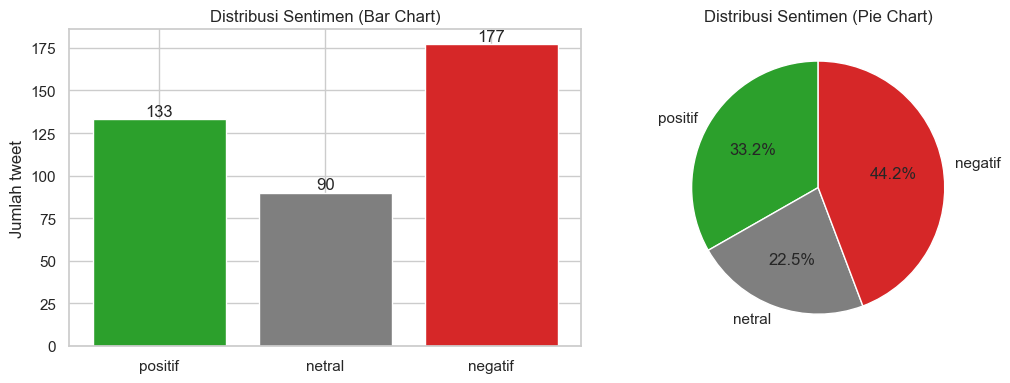

In [7]:
urutan = ["positif", "netral", "negatif"]
warna = {"positif": "#2ca02c", "netral": "#7f7f7f", "negatif": "#d62728"}
jumlah = df["sentimen"].value_counts().reindex(urutan).fillna(0).astype(int)
print(jumlah)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(jumlah.index, jumlah.values, color=[warna[k] for k in jumlah.index])
ax[0].set_title("Distribusi Sentimen (Bar Chart)")
ax[0].set_ylabel("Jumlah tweet")
for i, v in enumerate(jumlah.values):
    ax[0].text(i, v + 2, str(v), ha="center")
ax[1].pie(jumlah.values, labels=jumlah.index, autopct="%1.1f%%",
          colors=[warna[k] for k in jumlah.index], startangle=90)
ax[1].set_title("Distribusi Sentimen (Pie Chart)")
plt.tight_layout(); plt.show()

## Langkah 6 — Visualisasi WordCloud

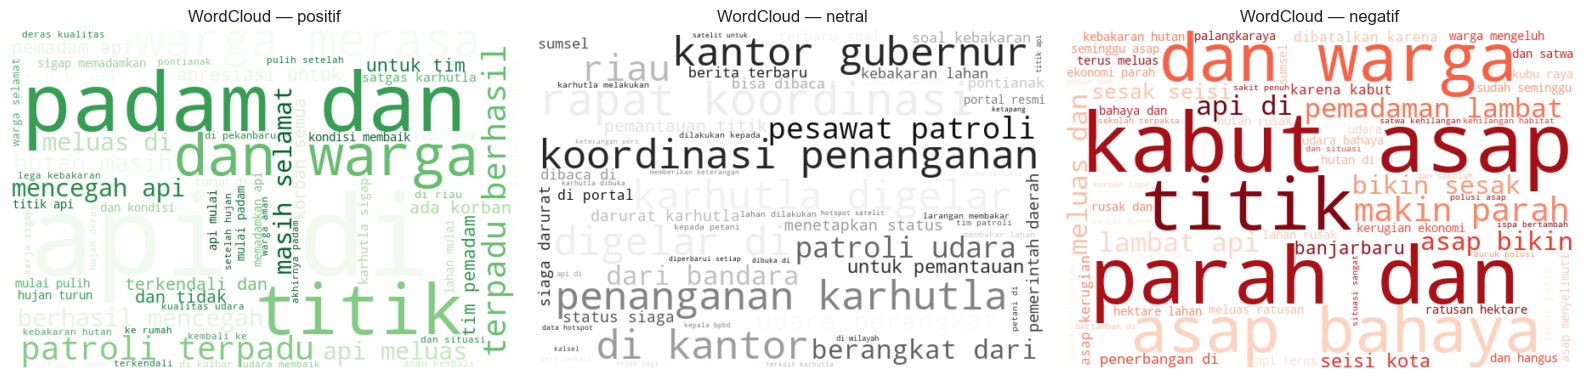

In [8]:
cmap = {"positif": "Greens", "netral": "Greys", "negatif": "Reds"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, kelas in zip(axes, urutan):
    teks = " ".join(df.loc[df["sentimen"] == kelas, "clean_text"])
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap=cmap[kelas], max_words=60).generate(teks)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"WordCloud — {kelas}")
plt.tight_layout(); plt.show()

## Langkah 7 — Model Neural Network (MLP)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["sentimen"], test_size=0.2, random_state=42, stratify=df["sentimen"])
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

tfidf = TfidfVectorizer()
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

mlp = MLPClassifier(hidden_layer_sizes=(100,), activation="relu", solver="adam",
                    max_iter=300, random_state=42)
mlp.fit(Xtr, y_train)
y_pred = mlp.predict(Xte)
print("Pelatihan selesai. Iterasi:", mlp.n_iter_)

Data latih: 320 | Data uji: 80
Pelatihan selesai. Iterasi: 141


## Langkah 8 — Evaluasi Model

In [10]:
hasil = pd.DataFrame({
    "Metrik": ["Akurasi", "Presisi (weighted)", "Recall (weighted)", "F1-Score (weighted)"],
    "Nilai": [accuracy_score(y_test, y_pred),
              precision_score(y_test, y_pred, average="weighted", zero_division=0),
              recall_score(y_test, y_pred, average="weighted", zero_division=0),
              f1_score(y_test, y_pred, average="weighted", zero_division=0)]})
display(hasil.round(4))
print(classification_report(y_test, y_pred, labels=urutan, zero_division=0))

,Metrik,Nilai
0,Akurasi,1.0
1,Presisi (weighted),1.0
2,Recall (weighted),1.0
3,F1-Score (weighted),1.0


              precision    recall  f1-score   support

     positif       1.00      1.00      1.00        27
      netral       1.00      1.00      1.00        18
     negatif       1.00      1.00      1.00        35

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80



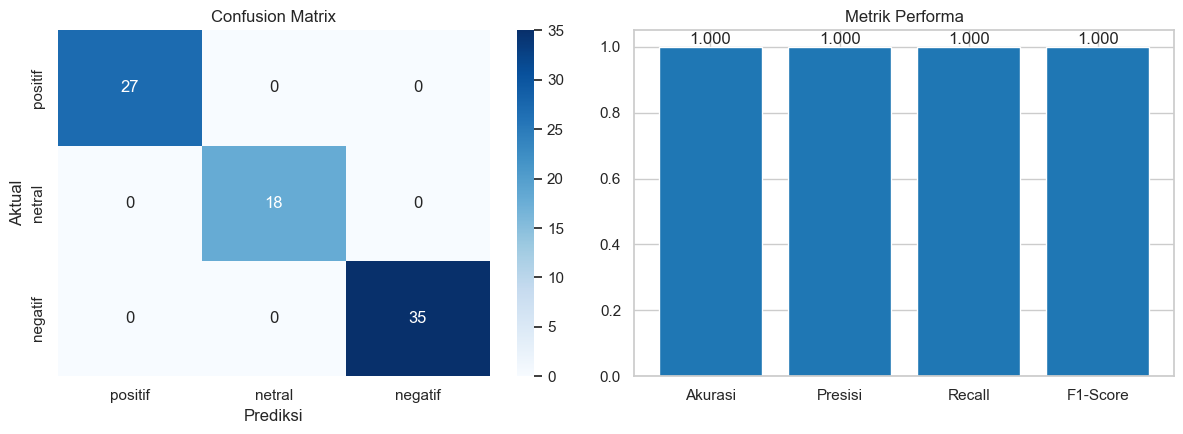

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=urutan)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=urutan, yticklabels=urutan, ax=ax[0])
ax[0].set_title("Confusion Matrix"); ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Aktual")
ax[1].bar(hasil["Metrik"].str.replace(" (weighted)", "", regex=False), hasil["Nilai"], color="#1f77b4")
ax[1].set_ylim(0, 1.05); ax[1].set_title("Metrik Performa")
for i, v in enumerate(hasil["Nilai"]):
    ax[1].text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

**Catatan interpretasi:** label dibuat dari kamus kata (rule-based), sedangkan fitur model adalah kata-kata yang sama (TF-IDF).
Karena itu model mudah "menghafal" aturan dan skor bisa sangat tinggi. Ini wajar untuk praktikum, tetapi belum membuktikan model
memahami sentimen sebenarnya; untuk data asli sebaiknya label diperiksa manual.

## Langkah 9 — Prediksi Teks Baru

In [12]:
emoji = {"positif": "😊", "netral": "😐", "negatif": "😡"}

def prediksi(teks):
    bersih = bersihkan(teks)
    vek = tfidf.transform([bersih])
    label = mlp.predict(vek)[0]
    proba = dict(zip(mlp.classes_, mlp.predict_proba(vek)[0]))
    return label, proba

for contoh in ["Asap karhutla makin parah, warga sesak napas dan mengungsi",
               "Api berhasil padam, warga lega dan aman",
               "BMKG merilis data titik panas hari ini"]:
    label, proba = prediksi(contoh)
    print(f"{emoji[label]} {label.upper():8s} | {contoh}")
    print("   probabilitas:", {str(k): round(float(v), 3) for k, v in proba.items()})

😡 NEGATIF  | Asap karhutla makin parah, warga sesak napas dan mengungsi
   probabilitas: {'negatif': 0.996, 'netral': 0.002, 'positif': 0.002}
😊 POSITIF  | Api berhasil padam, warga lega dan aman
   probabilitas: {'negatif': 0.004, 'netral': 0.005, 'positif': 0.991}
😐 NETRAL   | BMKG merilis data titik panas hari ini
   probabilitas: {'negatif': 0.011, 'netral': 0.978, 'positif': 0.012}
